# Sources: Offshore Wind, Expansion Targets and Existing Plants

The [basic tutorial](_2_basic_tutorial.ipynb) used three sources: wind turbines and PV, whose production is limited by a capacity factor (`operationRateMax`), and natural gas, which is bought at a price (`commodityCost`). This notebook adds two more sources to the same model and introduces the parameters they need:

| Component | New parameters | What they do |
|---|---|---|
| Offshore wind turbines | `locationalEligibility` | allows a component only in some regions |
| | `capacityMin` | sets a lower limit for the capacity, here per investment period |
| Run-of-river plants | `capacityFix` | fixes the capacity, e.g. for plants that already exist |
| | `operationRateFix` | fixes the hourly operation instead of only limiting it |

All of these parameters work the same way for the other component types (sinks, conversions, storages and transmissions).

## 1. The model of the basic tutorial

The function `buildBasicTutorialModel` in the file [basicTutorialModel.py](basicTutorialModel.py) next to this notebook builds exactly the model of the basic tutorial, so we do not have to repeat all of its code here. `readData` reads one of the CSV files in `examples/data/twoRegions`, like `pd.read_csv(..., index_col=0)` in the basic tutorial.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
from basicTutorialModel import (
    buildBasicTutorialModel,
    plotCapacityAndGeneration,
    readData,
)

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel()

## 2. Offshore wind turbines

Wind turbines at sea produce much more than on land, because the wind there is stronger and steadier. The data contains their capacity factors and potential. Only the north has a coast, so the potential in the south is 0:

In [2]:
offshoreCapacityFactor = readData("offshoreWindCapacityFactor.csv")
onshoreCapacityFactor = readData("windCapacityFactor.csv")
capacityPotential = readData("capacityPotential.csv")

pd.DataFrame(
    {
        "Mean capacity factor (offshore)": offshoreCapacityFactor.mean(),
        "Mean capacity factor (onshore)": onshoreCapacityFactor.mean(),
        "Potential (offshore) [GW]": capacityPotential.loc["Wind (offshore)"],
    }
).round(3)

,Mean capacity factor (offshore),Mean capacity factor (onshore),Potential (offshore) [GW]
north,0.496,0.257,81.0
south,0.000,0.179,0.0


In the north, an offshore wind turbine produces almost twice as much per GW as one on land. The two weeks of the basic tutorial show the difference:

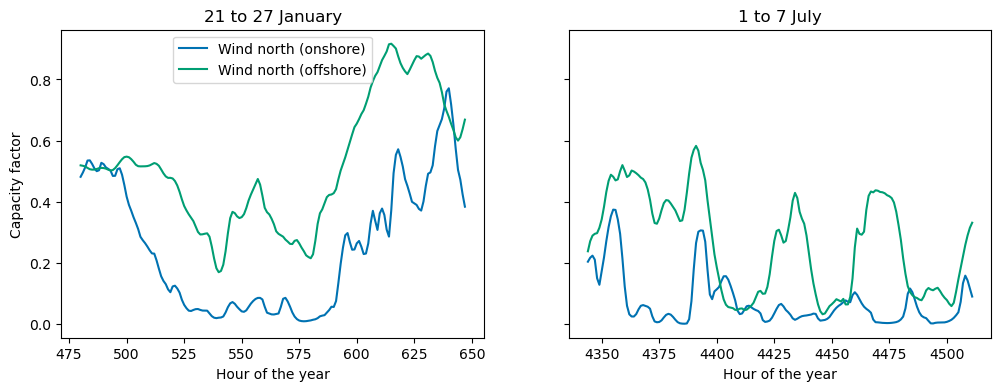

In [3]:
# Hours of the year in each week
weeks = {"21 to 27 January": range(480, 648), "1 to 7 July": range(4344, 4512)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, hours) in zip(axes, weeks.items()):
    onshoreCapacityFactor.loc[hours, "north"].plot(
        ax=ax, color="#0072B2", label="Wind north (onshore)"
    )
    offshoreCapacityFactor.loc[hours, "north"].plot(
        ax=ax, color="#009E73", label="Wind north (offshore)"
    )
    ax.set(title=title, xlabel="Hour of the year", ylabel="Capacity factor")
axes[0].legend(loc="upper center");

Two new parameters are used for the offshore wind turbines:

- **`locationalEligibility`**: a `pd.Series` with a 1 for every region in which the component may exist and a 0 for all others. For regions with a 0, FINE does not create any variables for the component, which also keeps the optimization problem small. If the parameter is not given, FINE derives it from other inputs such as `capacityMax` (a potential of 0 would also exclude the south) and otherwise allows every region. Setting it explicitly makes the intention clear, and FINE checks that the other inputs agree with it.
- **`capacityMin`**: a lower limit for the capacity. It accepts the same types as `capacityMax`: a number, a `pd.Series` per region, or a dictionary with the investment periods as keys. Germany's target for offshore wind is 30 GW in 2030. A dictionary has to contain every investment period, so 2020 and 2040 get a lower limit of 0, which means no limit. Since the target applies to the north only, the value for 2030 is a `pd.Series` per region.

In [4]:
esM.add(
    fn.Source(
        esM=esM,
        name="Offshore wind turbines",
        commodity="electricity",
        hasCapacityVariable=True,
        operationRateMax=offshoreCapacityFactor,
        locationalEligibility=pd.Series({"north": 1, "south": 0}),
        capacityMax=capacityPotential.loc["Wind (offshore)"],  # GW
        capacityMin={
            2020: 0,
            2030: pd.Series({"north": 30, "south": 0}),
            2040: 0,
        },  # GW
        investPerCapacity={2020: 4000, 2030: 3500, 2040: 3200},  # million Euro per GW
        opexPerCapacity=90,  # million Euro per GW and year
        interestRate=0.08,
        economicLifetime=25,
    )
)

## 3. Run-of-river plants

Run-of-river plants produce electricity from the flow of a river. Germany already has about 3.8 GW of them, almost all in the south (on the rivers of the Alps). We do not want FINE to decide whether to build them, they simply exist:

- **`capacityFix`** fixes the capacity in every region. We do not give any cost parameters: the plants exist already, so their investment is not part of the optimization.
- **`operationRateFix`** fixes the hourly operation. A run-of-river plant cannot store water, so it produces whatever the river provides. As for `operationRateMax`, the values are relative to the capacity, because the component has a capacity variable. (For a component without a capacity variable, such as the electricity demand in the basic tutorial, `operationRateFix` holds absolute values.)

The hourly profile is the same in both regions:

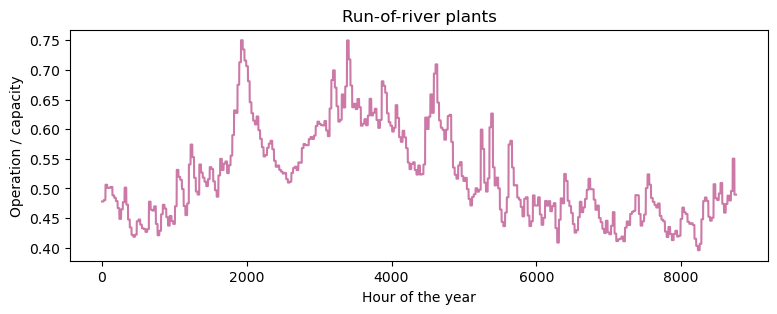

In [5]:
existingCapacity = readData("existingCapacity.csv")
runOfRiverProfile = readData("runOfRiverProfile.csv")

runOfRiverProfile["south"].plot(
    figsize=(9, 3),
    color="#CC79A7",
    xlabel="Hour of the year",
    ylabel="Operation / capacity",
    title="Run-of-river plants",
);

In [6]:
esM.add(
    fn.Source(
        esM=esM,
        name="Run-of-river plants",
        commodity="electricity",
        hasCapacityVariable=True,
        capacityFix=existingCapacity.loc["Run-of-river plants"],  # GW
        operationRateFix=runOfRiverProfile,
    )
)

## 4. Optimize

As in the basic tutorial, the model operates 8 typical days per investment period.

In [7]:
esM.aggregateTemporally(numberOfTypicalPeriods=8)

In [8]:
esM.optimize(
    timeSeriesAggregation=True,
    solver=fn.utils.ImplementedSolvers.STANDARD_SOLVER.value,
)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (75 outputs left out)

Solved with barrier


    2358    5.5261272e+05   0.000000e+00   0.000000e+00      1s


Solved in 2358 iterations and 0.66 seconds (0.51 work units)


Optimal objective  5.526127231e+05


## 5. Results

`plotCapacityAndGeneration` (also from `basicTutorialModel.py`) draws the bar charts of the basic tutorial for any list of generators, with both regions added up:

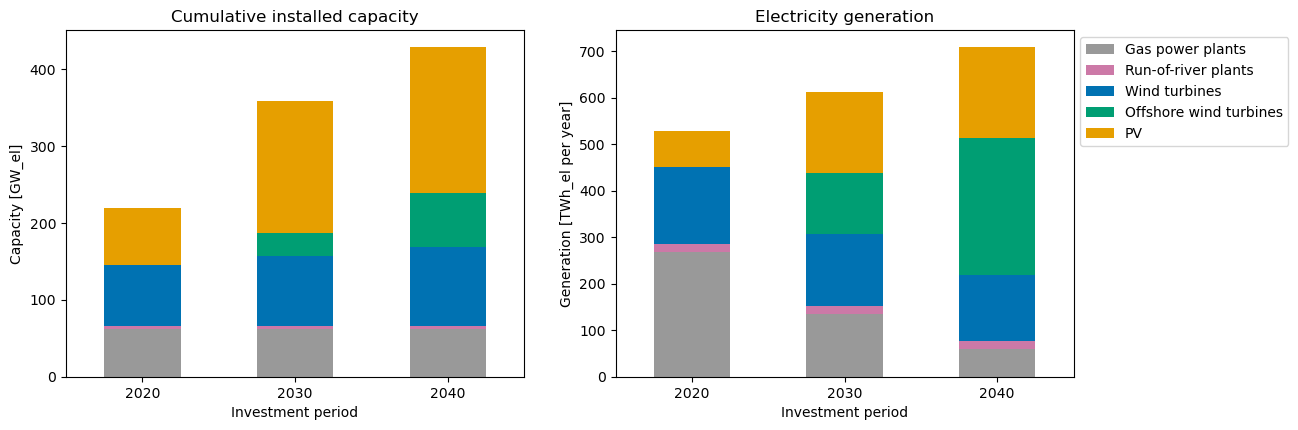

In [9]:
colors = {
    "Gas power plants": "#999999",
    "Run-of-river plants": "#CC79A7",
    "Wind turbines": "#0072B2",
    "Offshore wind turbines": "#009E73",
    "PV": "#E69F00",
}
capacity, generation = plotCapacityAndGeneration(esM, colors)

In [10]:
capacity.round(1)

,Gas power plants,Run-of-river plants,Wind turbines,Offshore wind turbines,PV
2020,61.9,3.8,79.2,0.0,74.2
2030,61.9,3.8,91.4,30.0,172.1
2040,61.9,3.8,102.4,71.5,189.7


The new sources change the system considerably:

- The **run-of-river plants** have exactly their fixed capacity of 3.8 GW and produce about 17 TWh per year in every period, almost all of it in the south.
- The **offshore wind turbines** are still too expensive in 2020. In 2030, the model builds exactly the 30 GW of the target: the lower limit is binding, so without it, the model would build less. By 2040, offshore wind has become cheaper and grows to about 71 GW without any target. It is then the largest source of electricity (about 290 TWh, 40 % of the generation).
- Offshore wind replaces most of the **onshore wind turbines**: in 2040, only about 100 GW are built on land, compared with about 380 GW in the basic tutorial. Since offshore turbines produce more steadily, the system also needs fewer batteries (about 220 GWh instead of 500 GWh in 2040).

The total discounted cost of the system, which FINE stores in `esM.objectiveValue` after the optimization, drops from about 596 billion Euro in the basic tutorial to about 553 billion Euro:

In [11]:
round(esM.objectiveValue)  # million Euro

552613

## Things to try

- Remove `capacityMin`. How much offshore wind does the model build without the target, and how much does the target cost (compare `esM.objectiveValue`, the total discounted cost)?
- Give the offshore wind turbines a target for 2040 as well, e.g. 50 GW.
- Set `capacityMax` of the onshore wind turbines in the north to half of the potential, e.g. because of limited acceptance. How does the system react?

The next notebook, [Sinks](_4_sinks.ipynb), replaces the CO<sub>2</sub> limit by a CO<sub>2</sub> price and adds electricity exports.